<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/Arsenicosis_Corrected_Evaluation_Results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf

SOURCE_DIR = '/content/drive/MyDrive/ArsenicSkinImage(BD)/Augmented'
AUGMENTED_DIR = '/content/Augmented'
SPLIT_DIR = '/content/Split_Dataset'

MODEL_PATH = '/content/drive/MyDrive/Thesis_Model/Best_Model.keras'
OUTPUT_DIR = '/content/drive/MyDrive/Thesis_Model/Corrected_Evaluation'

os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(SOURCE_DIR):
    raise FileNotFoundError(f"Dataset not found: {SOURCE_DIR}")

if os.path.exists(AUGMENTED_DIR):
    shutil.rmtree(AUGMENTED_DIR)

shutil.copytree(SOURCE_DIR, AUGMENTED_DIR)

print("Dataset copied successfully.")
print("TensorFlow version:", tf.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset copied successfully.
TensorFlow version: 2.21.0


In [2]:
from sklearn.model_selection import GroupShuffleSplit

classes = ['infected', 'not_infected']

records = []

for class_name in classes:
    class_dir = os.path.join(AUGMENTED_DIR, class_name)

    if not os.path.exists(class_dir):
        raise FileNotFoundError(f"Class folder not found: {class_dir}")

    for filename in os.listdir(class_dir):
        if filename.lower().endswith('.png'):
            group_id = filename.split('_augmented')[0].split('.')[0]

            records.append({
                'filepath': os.path.join(class_dir, filename),
                'filename': filename,
                'class_name': class_name,
                'group_id': group_id
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Total source groups:", df['group_id'].nunique())
print("\nClass distribution:")
print(df['class_name'].value_counts())

# First split: 70% training, 30% temporary
gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(df, groups=df['group_id'])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: 15% validation, 15% test
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(temp_df, groups=temp_df['group_id'])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("\nTrain images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

# Check group leakage
train_groups = set(train_df['group_id'])
val_groups = set(val_df['group_id'])
test_groups = set(test_df['group_id'])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\nGroup leakage check passed.")

Total images: 8892
Total source groups: 1482

Class distribution:
class_name
infected        4446
not_infected    4446
Name: count, dtype: int64

Train images: 6222
Validation images: 1332
Test images: 1338

Group leakage check passed.


In [3]:
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

split_data = {
    'Train': train_df,
    'Validation': val_df,
    'Test': test_df
}

for split_name, split_df in split_data.items():

    for class_name in classes:
        os.makedirs(
            os.path.join(SPLIT_DIR, split_name, class_name),
            exist_ok=True
        )

    for _, row in split_df.iterrows():

        destination = os.path.join(
            SPLIT_DIR,
            split_name,
            row['class_name'],
            row['filename']
        )

        shutil.copy2(row['filepath'], destination)

print("Train, Validation and Test folders created.")

Train, Validation and Test folders created.


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_generator = test_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'Test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=classes,
    shuffle=False
)

print("Class mapping:", test_generator.class_indices)
print("Test samples:", test_generator.samples)

assert test_generator.class_indices == {
    'infected': 0,
    'not_infected': 1
}

Found 1338 images belonging to 2 classes.
Class mapping: {'infected': 0, 'not_infected': 1}
Test samples: 1338


In [5]:
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Saved model not found: {MODEL_PATH}"
    )

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

model.summary()

print("\nPreviously trained model loaded successfully.")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,949,586 (125.69 MB)

 Trainable params: 27,848,114 (106.23 MB)

 Non-trainable params: 5,101,472 (19.46 MB)


Previously trained model loaded successfully.


In [6]:
from sklearn.metrics import classification_report

# True labels
y_true = test_generator.classes

# Predicted probabilities
y_pred_prob = model.predict(
    test_generator,
    verbose=1
)

# Predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)
print("y_pred_prob shape:", y_pred_prob.shape)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=['Infected', 'Non-infected'],
        digits=4
    )
)

42/42 ━━━━━━━━━━━━━━━━━━━━ 60s 750ms/step
y_true shape: (1338,)
y_pred shape: (1338,)
y_pred_prob shape: (1338, 2)

Classification Report:
              precision    recall  f1-score   support

    Infected     0.9982    0.9873    0.9927       552
Non-infected     0.9912    0.9987    0.9949       786

    accuracy                         0.9940      1338
   macro avg     0.9947    0.9930    0.9938      1338
weighted avg     0.9941    0.9940    0.9940      1338



In [7]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Infected = Positive Class (Class 0)
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, pos_label=0, zero_division=0)
f1 = f1_score(y_true, y_pred, pos_label=0, zero_division=0)
mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nMedical Performance Metrics")
print(f"TP: {TP}")
print(f"FN: {FN}")
print(f"FP: {FP}")
print(f"TN: {TN}")

print(f"\nAccuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Sensitivity: {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"Specificity: {specificity:.4f} ({specificity*100:.2f}%)")
print(f"Precision:   {precision:.4f} ({precision*100:.2f}%)")
print(f"F1-score:    {f1:.4f} ({f1*100:.2f}%)")
print(f"MCC:         {mcc:.4f}")
print(f"Kappa:       {kappa:.4f}")

Confusion Matrix:
[[545   7]
 [  1 785]]

Medical Performance Metrics
TP: 545
FN: 7
FP: 1
TN: 785

Accuracy:    0.9940 (99.40%)
Sensitivity: 0.9873 (98.73%)
Specificity: 0.9987 (99.87%)
Precision:   0.9982 (99.82%)
F1-score:    0.9927 (99.27%)
MCC:         0.9877
Kappa:       0.9876


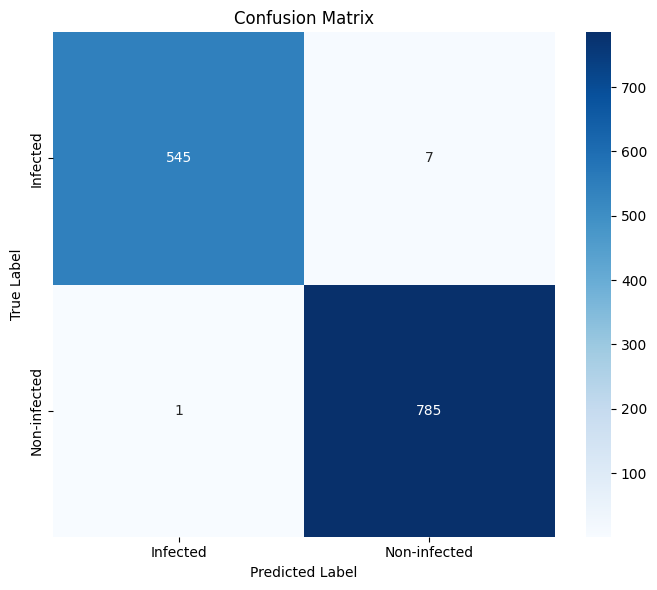

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

class_names = ['Infected', 'Non-infected']

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'Confusion_Matrix.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

ROC-AUC: 0.9999


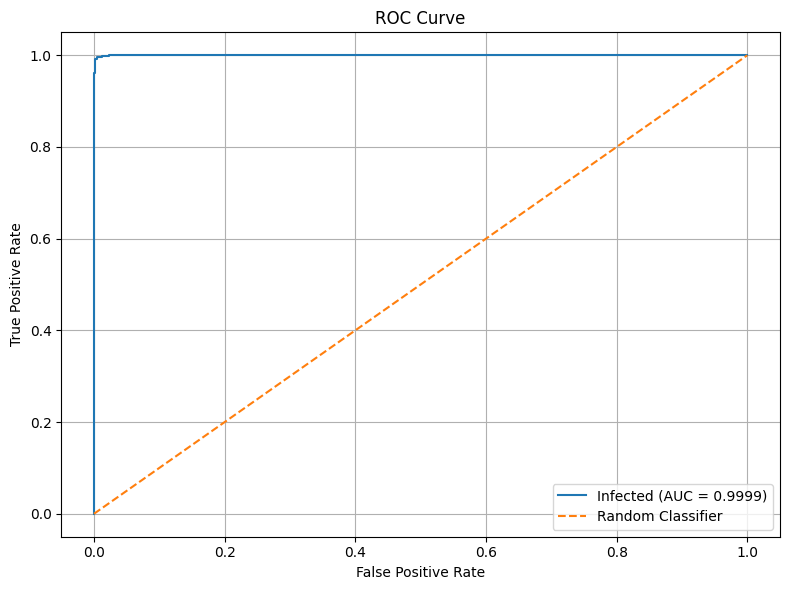

In [9]:
from sklearn.metrics import roc_curve, auc

y_true_infected = (y_true == 0).astype(int)
y_score = y_pred_prob[:, 0]

fpr, tpr, roc_thresholds = roc_curve(
    y_true_infected,
    y_score
)

roc_auc = auc(fpr, tpr)

print(f"ROC-AUC: {roc_auc:.4f}")

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Infected (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'ROC_Curve.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Average Precision: 0.9998
Positive Class Prevalence: 0.4126


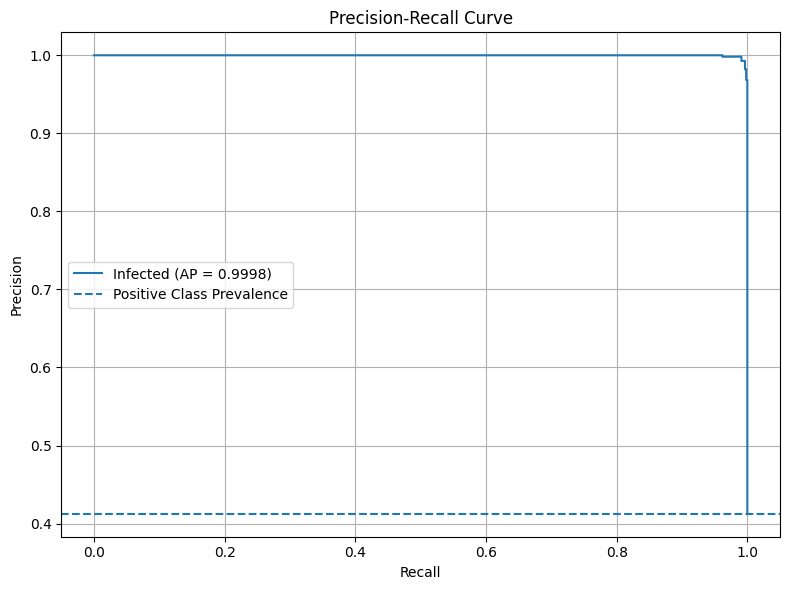

In [10]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_true_infected,
        y_score
    )
)

average_precision = average_precision_score(
    y_true_infected,
    y_score
)

positive_prevalence = np.mean(y_true_infected)

print(f"Average Precision: {average_precision:.4f}")
print(f"Positive Class Prevalence: {positive_prevalence:.4f}")

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f'Infected (AP = {average_precision:.4f})'
)

plt.axhline(
    positive_prevalence,
    linestyle='--',
    label='Positive Class Prevalence'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'PR_Curve.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [11]:
# Performance metrics
metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Sensitivity',
        'Specificity',
        'Precision',
        'F1-Score',
        'ROC-AUC',
        'Average Precision',
        'MCC',
        'Cohen Kappa'
    ],
    'Value': [
        accuracy,
        sensitivity,
        specificity,
        precision,
        f1,
        roc_auc,
        average_precision,
        mcc,
        kappa
    ]
})

# Confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=['Actual Infected', 'Actual Non-infected'],
    columns=['Predicted Infected', 'Predicted Non-infected']
)

# Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=['Infected', 'Non-infected'],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Save Excel
excel_path = os.path.join(
    OUTPUT_DIR,
    'Corrected_Performance_Metrics.xlsx'
)

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    metrics_df.to_excel(
        writer,
        sheet_name='Performance Metrics',
        index=False
    )

    cm_df.to_excel(
        writer,
        sheet_name='Confusion Matrix'
    )

    report_df.to_excel(
        writer,
        sheet_name='Classification Report'
    )

# Save CSV files
metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Performance_Metrics.csv'),
    index=False
)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Confusion_Matrix.csv')
)

report_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Classification_Report.csv')
)

# Save ROC data
pd.DataFrame({
    'FPR': fpr,
    'TPR': tpr
}).to_csv(
    os.path.join(OUTPUT_DIR, 'ROC_Data.csv'),
    index=False
)

# Save PR data
pd.DataFrame({
    'Recall': recall_curve,
    'Precision': precision_curve
}).to_csv(
    os.path.join(OUTPUT_DIR, 'PR_Data.csv'),
    index=False
)

# Save predictions
prediction_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Actual_Label': [
        classes[i] for i in y_true
    ],
    'Predicted_Label': [
        classes[i] for i in y_pred
    ],
    'Infected_Probability': y_pred_prob[:, 0],
    'Non_Infected_Probability': y_pred_prob[:, 1]
})

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Test_Predictions.csv'),
    index=False
)

print("All corrected evaluation files saved successfully.")
print("Output folder:", OUTPUT_DIR)
print("Excel file:", excel_path)

All corrected evaluation files saved successfully.
Output folder: /content/drive/MyDrive/Thesis_Model/Corrected_Evaluation
Excel file: /content/drive/MyDrive/Thesis_Model/Corrected_Evaluation/Corrected_Performance_Metrics.xlsx


In [12]:
import os

print("Checking evaluation output files...\n")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    filepath = os.path.join(OUTPUT_DIR, filename)

    if os.path.isfile(filepath):
        print(f"{filename}  |  {os.path.getsize(filepath)/1024:.2f} KB")

print("\nOutput folder:", OUTPUT_DIR)

Checking evaluation output files...

Classification_Report.csv  |  0.41 KB
Confusion_Matrix.csv  |  0.09 KB
Confusion_Matrix.png  |  82.74 KB
Corrected_Performance_Metrics.xlsx  |  6.41 KB
PR_Curve.png  |  91.11 KB
PR_Data.csv  |  30.37 KB
Performance_Metrics.csv  |  0.27 KB
ROC_Curve.png  |  120.43 KB
ROC_Data.csv  |  0.64 KB
Test_Predictions.csv  |  112.22 KB

Output folder: /content/drive/MyDrive/Thesis_Model/Corrected_Evaluation


In [1]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Thesis_Model/Best_Model.keras",
    compile=False
)

model.summary()

print("\nTotal parameters:", model.count_params())
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in model.trainable_weights))
print("Non-trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in model.non_trainable_weights))

print("\nLayer-wise parameter count:")
for layer in model.layers:
    if layer.count_params() > 0:
        print(
            f"{layer.name:45s} "
            f"{layer.count_params():,} "
            f"Trainable={layer.trainable}"
        )

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,949,586 (125.69 MB)

 Trainable params: 27,848,114 (106.23 MB)

 Non-trainable params: 5,101,472 (19.46 MB)


Total parameters: 32949586
Trainable parameters: 27848114
Non-trainable parameters: 5101472

Layer-wise parameter count:
stem_conv                                     864 Trainable=False
stem_bn                                       128 Trainable=False
block1a_project_conv                          4,608 Trainable=False
block1a_project_bn                            64 Trainable=False
block2a_expand_conv                           9,216 Trainable=False
block2a_expand_bn                             256 Trainable=False
block2a_project_conv                          2,048 Trainable=False
block2a_project_bn                            128 Trainable=False
block2b_expand_conv                           36,864 Trainable=False
block2b_expand_bn                             512 Trainable=False
block2b_project_conv                          4,096 Trainable=False
block2b_project_bn                            128 Trainable=False
block3a_expand_conv                           36,864 Trainable=False
block3a